# ขั้นที่ 7: ทดลอง feature engineering — งานที่ 2 (พิกัด → โอกาสพบซาก / ประเภทซาก)

เทียบชุด feature เดิมของ notebook 10 (`base` = พันเจีย + DEM + ธรณีวิทยา + Sentinel-2) กับการเพิ่มกลุ่มใหม่จาก notebook 13 ทีละกลุ่มและรวมกัน

| ชุด | เพิ่มจาก base |
|---|---|
| `+geo` | ธรณี+ (`gx_`: รอยเลื่อน, ชั้นหินโค้ง, รอยสัมผัสหน่วยหิน, ชนิดหิน ThaiLex) + พันเจีย+ (`pgx_`: ระยะถึงชายฝั่งโบราณ) |
| `+surface` | ผิวดิน / น้ำ / การกัดเซาะ (`lc_`: WorldCover, น้ำผิวดิน, ลำน้ำ, TerraClimate) |
| `+spatial` | บริบทเชิงพื้นที่ (`sc_`: ความหนาแน่นแหล่งที่รู้จัก, ระยะถึงแหล่งใกล้สุด, อัตราพบซากต่อพื้นที่หน่วยหินแบบ PFYC; ขั้น B: ประเภทซากของแหล่งใกล้เคียง) |
| `+geo+surface`, `+geo+surface+spatial` | รวมกลุ่มธรรมชาติ |
| `+discovery`, `discovery_only` | การเข้าถึง (`dc_`: ถนน, บ่อหิน, พื้นที่แร่, อ่างเก็บน้ำ) — **ทดลองแยก ไม่ใช้ในโมเดลตัวจริง** (ตามที่ตกลง) |
| `base-<กลุ่ม>` | **ตัดทีละกลุ่ม**จาก base ของโมเดลตัวจริง: `pangea` (`pg_` ทั้งหมด รวมแผ่นเปลือกโลก / terrane), `dem`, `geology`, `s2` |
| `full-<กลุ่ม>` | ตัดทีละกลุ่มจากชุดเต็ม `+geo+surface+spatial`: `pangea`, `dem`, `geology`, `s2`, `geo_plus`, `surface` (ตัด `spatial` = ชุด `+geo+surface`) |

**บริบทเชิงพื้นที่ (out-of-fold)**: ใช้ label ของแหล่ง จึงคำนวณใหม่ทุก (แบบ CV, fold) จากแหล่ง ทธ. ใน fold train เท่านั้น
และ*ไม่นับแหล่งในกลุ่มเดียวกับแถวนั้น* ตามแบบ CV (`site_cluster` = กลุ่ม 2 กม., `spatial_block` = บล็อก 50 กม., `random` = ตัวเอง)
→ แถว train กับแถวทดสอบได้ feature แบบเดียวกัน; ตอนใช้จริงคำนวณจากแหล่งทั้งหมด

ทดลองด้วย LightGBM (เร็ว) ทุกชุด + XGBoost (ขั้น A) / Random Forest (ขั้น B) ซึ่งเป็นโมเดลตัวจริงของ notebook 10 กับชุดหลักและชุดตัดทีละกลุ่มจาก base;
ตัวเลขหลัก = `spatial_block`;
PBDB ทดสอบแบบ out-of-fold (collection PBDB ใน fold k ทำนายด้วยโมเดลของ fold k) — **รันต่อได้**: ผลทุก (ชุด, fold) อยู่ใน `models/task2/FE/`

In [1]:
import sys

sys.path.insert(0, ".")
import model_lib as ml
import feature_lib as fl

import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from sklearn.neighbors import BallTree

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.width", 180)
INK, MUTED = "#52514e", "#8a8984"
cv_color = {"random": "#bdbcb6", "site_cluster": "#86b6ef", "spatial_block": "#2a78d6"}
ml.seed_everything(42)
OUT = ml.MODELS / "task2" / "FE"
(OUT / "sc_v2").mkdir(parents=True, exist_ok=True)
META = json.loads((ml.MODELS / "task2" / "final" / "final_meta.json").read_text(encoding="utf-8"))

## 1. ข้อมูลและชุด feature

In [2]:
allf = (pd.read_parquet(ml.FEAT / "all_features.parquet").merge(pd.read_parquet(ml.FEAT / "folds.parquet"), on="point_id")
        .merge(pd.read_parquet(ml.FEAT / "extra_features.parquet"), on="point_id", how="left"))
CAT = ["pg_sw18_plate", "pg_me21_plate", "pg_me21_terrane", "geo_rock_sym", "geo_era_old", "geo_era_young", "geo_rock_kind", "oc_nearest_rock"]
for c in CAT:
    allf[c] = allf[c].astype(str)
BASE = (META["features"]["num"], META["features"]["cat"])
grp = {g: [c for c in allf.columns if c.startswith(p)] for g, p in fl.EXTRA_GROUPS.items()}
print({g: len(v) for g, v in grp.items()})

# label ประเภทซาก (เหมือน notebook 10 หลังแก้ label ชื่อสถานที่)
spec = pd.read_csv(ml.DATA / "processed" / "fossil_list_final.csv", dtype={"fossil_id": str, "site_OBJECTID": "Int64"}, encoding="utf-8-sig", low_memory=False)
hm = spec[spec.confidence.isin(["high", "medium"])].copy()
hm["cls"] = [fl.specimen_classes(t, c) for t, c in zip(hm.f_type, hm.com_name)]
hm = hm.assign(sid=hm.tied_site_ids.str.split(";")).explode("sid")
from_spec = hm.groupby(hm.sid.astype(float).astype(int)).cls.agg(lambda s: set().union(*s))
raw = gpd.read_file(ml.DATA / "dmr_fossil_sites" / "fossil_sites.geojson")[["OBJECTID", "NAME_TH", "FOS_DES_TH"]]
from_text = {int(o): fl.classes_of(f"{n or ''} {d or ''}") for o, n, d in zip(raw.OBJECTID, raw.NAME_TH, raw.FOS_DES_TH)}
KEEP = META["classes_B"]
sites = allf[allf.source.eq("dmr_site")].copy()
sites["labels"] = [from_spec.get(int(p[4:]), set()) | from_text.get(int(p[4:]), set()) for p in sites.point_id]
print("คลาสขั้น B:", len(KEEP), KEEP)

{'geo_plus': 30, 'surface': 18, 'discovery': 6}


คลาสขั้น B: 16 ['ไดโนเสาร์', 'สัตว์เลื้อยคลานอื่น', 'ปลา', 'สัตว์เลี้ยงลูกด้วยนม', 'แบรคิโอพอด', 'หอยสองฝา', 'หอยฝาเดียว', 'เซฟาโลพอด', 'ปะการัง', 'ไครนอยด์', 'ไบรโอซัว', 'ไทรโลไบต์', 'แกรปโตไลต์', 'ฟอแรม/ฟิวซูลินิด', 'พืช', 'ร่องรอย']


## 2. บริบทเชิงพื้นที่แบบ out-of-fold (`sc_`)

ต่อ (แบบ CV, fold k): แหล่งอ้างอิง = แหล่ง ทธ. ที่ fold ≠ k; ทุกแถว (แหล่ง, background, PBDB) ไม่นับแหล่งอ้างอิงที่อยู่กลุ่มเดียวกับตัวเอง
- `sc_dist_site_km` ระยะถึงแหล่งอ้างอิงใกล้สุด; `sc_kde_10km`, `sc_kde_50km` ความหนาแน่นแบบ Gaussian; `sc_n_25km` จำนวนใน 25 กม.
- `sc_unit_rate` อัตราพบแหล่งต่อ 1,000 กม.² ของหน่วยหินที่จุดอยู่ (คล้าย PFYC แต่คำนวณจากข้อมูล)
- ขั้น B: `sc_type_<ประเภท>` สัดส่วนถ่วงน้ำหนักระยะ (σ = 15 กม.) ของแหล่งอ้างอิงในรัศมี 100 กม. ที่มีประเภทนั้น

In [3]:
# ฟังก์ชันอยู่ใน feature_lib (fl.spatial_context) เพื่อให้แผนที่ (10b) และ inference (12) ใช้โค้ดเดียวกัน
SC = {}
GROUP = {"random": None, "site_cluster": "group_site_cluster", "spatial_block": "group_spatial_block"}
# cache ต่อ (แบบ CV, fold) ใน models/task2/FE/sc_v2/ ใช้ซ้ำเฉพาะเมื่อ fingerprint ของข้อมูลนำเข้า + โค้ดตรงกับปัจจุบัน
SC_CODE = ml.code_hash(fl.spatial_context, fl.unit_areas) + ml.file_hash(fl.EXTRA_DIR / "gx_rock_code.npz") + ml.file_hash(fl.EXTRA_DIR / "rock_codes.json")


def sc_fold(cv, k):
    ref = sites[sites[f"fold_{cv}"] != k]
    g = GROUP[cv] or "point_id"
    cols = ["point_id", "lon", "lat", "geo_rock_sym", g]

    def compute():
        s = fl.spatial_context(allf, ref, allf[g].values, ref[g].values, list(ref.labels), KEEP)
        s.insert(0, "point_id", allf.point_id.values)
        return s
    fp = ml.fingerprint(allf[list(dict.fromkeys(cols))].astype(str), ref[list(dict.fromkeys(cols))].astype(str),
                        ref.labels.map(lambda x: "|".join(sorted(x))), KEEP, SC_CODE)
    return ml.cached_frame(OUT / "sc_v2" / f"{cv}__f{k}.parquet", fp, compute)


for cv in ml.tqdm_auto()(ml.CV_SCHEMES, desc="บริบทเชิงพื้นที่"):
    for k in range(ml.N_FOLDS):
        SC[cv, k] = sc_fold(cv, k)
SC_A = fl.SC_A
SC_B = SC_A + ["sc_n_labelled_100km"] + [f"sc_type_{c}" for c in KEEP]
d = SC["spatial_block", 0].merge(allf[["point_id", "source", "fold_spatial_block"]], on="point_id")
print("ตัวอย่าง (spatial_block fold 0): ระยะถึงแหล่งอ้างอิงใกล้สุด (กม.) — แหล่ง train vs แหล่งทดสอบ")
print(d[d.source.eq("dmr_site")].groupby(d.fold_spatial_block.eq(0).map({True: "test", False: "train"})).sc_dist_site_km.describe().round(1))

บริบทเชิงพื้นที่: 100%|██████████| 3/3 [00:00<00:00,  5.10it/s]


ตัวอย่าง (spatial_block fold 0): ระยะถึงแหล่งอ้างอิงใกล้สุด (กม.) — แหล่ง train vs แหล่งทดสอบ
                    count  mean   std  min   25%   50%   75%    max
fold_spatial_block                                                 
test                 75.0  31.5  19.3  3.3  17.4  31.6  37.4  100.0
train               443.0  23.3  14.8  1.1  11.6  20.7  31.1  100.0


## 3. การทดลอง

In [4]:
FS = {
    "base": BASE,
    "+geo": (BASE[0] + grp["geo_plus"], BASE[1]),
    "+surface": (BASE[0] + grp["surface"], BASE[1]),
    "+spatial": (BASE[0] + ["@sc"], BASE[1]),
    "+geo+surface": (BASE[0] + grp["geo_plus"] + grp["surface"], BASE[1]),
    "+geo+surface+spatial": (BASE[0] + grp["geo_plus"] + grp["surface"] + ["@sc"], BASE[1]),
    "+discovery": (BASE[0] + grp["discovery"], BASE[1]),
    "discovery_only": (grp["discovery"], []),
}
FE_SETS = list(FS)                       # ชุดเพิ่มกลุ่ม (ใช้ในกราฟ)

# ตัดทีละกลุ่ม (leave-one-group-out): จาก base ของโมเดลตัวจริง และจากชุดเต็ม — ตอบว่าแต่ละกลุ่มช่วยจริงไหม
DROP_GROUPS = {"pangea": ("pg_",), "dem": ("dem_",), "geology": ("geo_",), "s2": ("s2_",), "geo_plus": ("gx_", "pgx_"), "surface": ("lc_",)}
BASE_GROUPS = ["pangea", "dem", "geology", "s2"]


def without(fs, g):
    num, cat = FS[fs]
    return [c for c in num if not c.startswith(DROP_GROUPS[g])], [c for c in cat if not c.startswith(DROP_GROUPS[g])]


LOGO_BASE = [f"base-{g}" for g in BASE_GROUPS]
LOGO_FULL = [f"full-{g}" for g in DROP_GROUPS]
for g in BASE_GROUPS:
    FS[f"base-{g}"] = without("base", g)
for g in DROP_GROUPS:
    FS[f"full-{g}"] = without("+geo+surface+spatial", g)
display(pd.DataFrame({k: {"numeric": len([c for c in v[0] if c != "@sc"]) + (len(SC_A) if "@sc" in v[0] else 0), "categorical": len(v[1])}
                      for k, v in FS.items()}).T.rename_axis("ชุด (ขั้น A)"))


def cols_for(fs, stage):
    num, cat = FS[fs]
    sc = SC_A if stage == "A" else SC_B
    return [c for c in num if c != "@sc"] + (sc if "@sc" in num else []), cat


def run(reg, d, Y, cv, model, fs, stage, task="binary", classes=None):
    exp = f"{cv}__{model}@{fs}"
    num, cat = cols_for(fs, stage)
    for k in range(ml.N_FOLDS):
        dk = d.merge(SC[cv, k], on="point_id", how="left") if any(c.startswith("sc_") for c in num) else d
        ml.run_tabular_cv(reg, exp, dk, Y, f"fold_{cv}", model, num, cat, task=task, classes=classes, only_folds=[k])


regA = {bg: ml.Registry(OUT / f"A_{bg}") for bg in ["bg_bias", "bg_uniform"]}
XGB_SETS = ["base", "+geo+surface", "+geo+surface+spatial"] + LOGO_BASE    # ขั้น A: XGBoost, ขั้น B: Random Forest
for bg, reg in regA.items():
    d = allf[allf.source.isin(["dmr_site", bg])].reset_index(drop=True)
    y = d.source.eq("dmr_site").astype(int).values
    jobs = [(cv, "lgbm", fs) for cv in ml.CV_SCHEMES for fs in FS] + [(cv, "xgb", fs) for cv in ml.CV_SCHEMES for fs in XGB_SETS]
    for cv, m, fs in ml.tqdm_auto()(jobs, desc=f"ขั้น A {bg}"):
        run(reg, d, y, cv, m, fs, "A")

,numeric,categorical
ชุด (ขั้น A),,
base,145,7
+geo,175,7
+surface,163,7
+spatial,150,7
+geo+surface,193,7
+geo+surface+spatial,198,7
+discovery,151,7
discovery_only,6,0
base-pangea,63,4


ขั้น A bg_uniform: 100%|██████████| 75/75 [00:21<00:00,  3.49it/s]


In [5]:
dB = sites[sites.labels.map(lambda s: bool(s & set(KEEP)))].reset_index(drop=True)
YB = np.array([[int(c in s) for c in KEEP] for s in dB.labels])
regB = ml.Registry(OUT / "B_v2")              # label ขั้น B หลังตรวจทาน (ชื่อสถานที่เพิ่ม ภูเต่า / เขาปลาร้า)
jobs = [(cv, "lgbm", fs) for cv in ml.CV_SCHEMES for fs in FS if fs != "discovery_only"] + [(cv, "rf", fs) for cv in ml.CV_SCHEMES for fs in XGB_SETS]
for cv, m, fs in ml.tqdm_auto()(jobs, desc="ขั้น B"):
    run(regB, dB, YB, cv, m, fs, "B", task="multilabel", classes=KEEP)

spatial_block__rf@base-s2:   0%|          | 0/1 [00:00<?, ?it/s]


## 4. ผล

In [6]:
def table(reg, metric):
    r = reg.results()
    r = r.assign(cv=r.exp.str.split("__").str[0], m=r.exp.str.split("__").str[1])
    return r.groupby(["m", "cv"])[metric].mean().unstack()[ml.CV_SCHEMES]


ORDER = [f"{m}@{fs}" for m in ["lgbm", "xgb"] for fs in FS]
tA = pd.concat({bg: table(regA[bg], "auc").reindex([o for o in ORDER if o in table(regA[bg], "auc").index]) for bg in regA}, axis=1)
display(tA.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))
tB = table(regB, "macro_auc")
display(tB.reindex([o for o in [f"{m}@{fs}" for m in ["lgbm", "rf"] for fs in FS] if o in tB.index]).style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

cv,random,site_cluster,spatial_block
m,,,
lgbm@base,0.817,0.765,0.742
lgbm@+geo,0.817,0.770,0.741
lgbm@+surface,0.814,0.764,0.735
lgbm@+spatial,0.816,0.774,0.745
lgbm@+geo+surface,0.816,0.766,0.744
lgbm@+geo+surface+spatial,0.817,0.771,0.741
lgbm@+discovery,0.820,0.768,0.743
lgbm@base-pangea,0.814,0.760,0.740
lgbm@base-dem,0.817,0.772,0.744


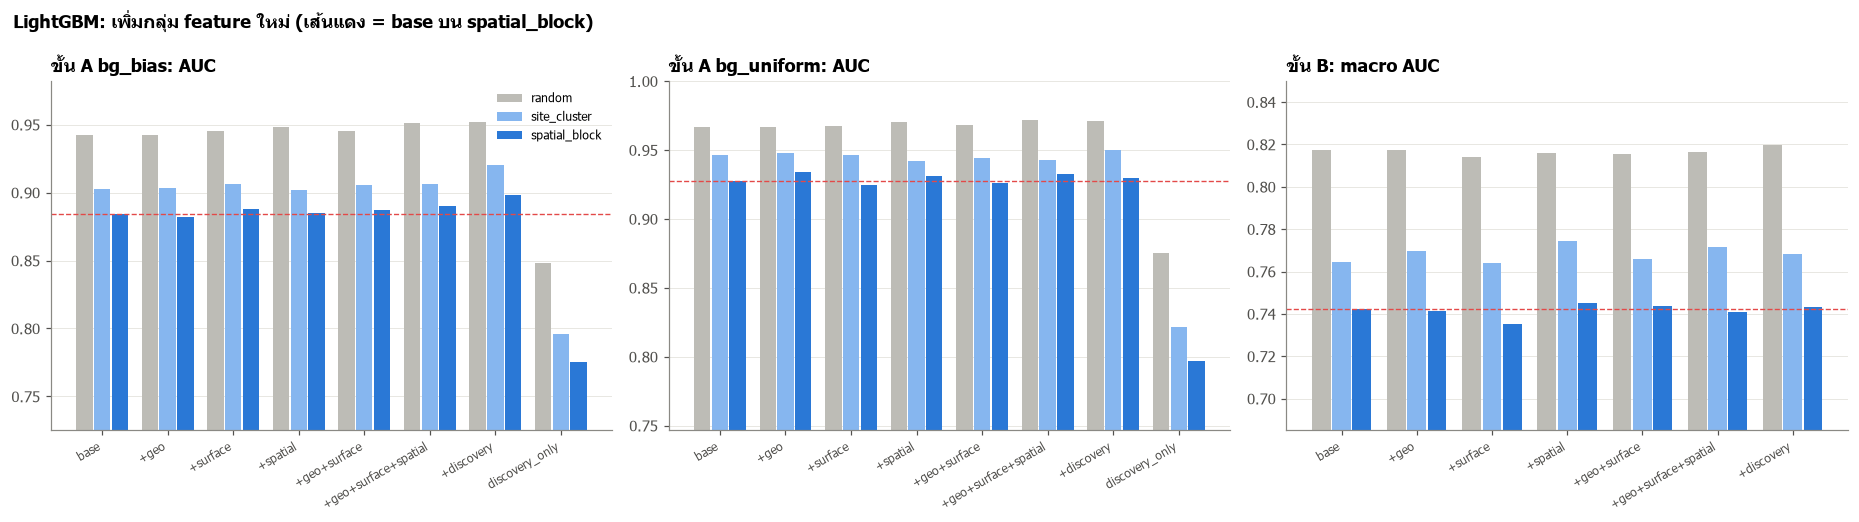

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=False)
for ax, (title, t) in zip(axes, [("ขั้น A bg_bias: AUC", table(regA["bg_bias"], "auc")), ("ขั้น A bg_uniform: AUC", table(regA["bg_uniform"], "auc")),
                                  ("ขั้น B: macro AUC", table(regB, "macro_auc"))]):
    t = t.reindex([f"lgbm@{fs}" for fs in FE_SETS]).dropna(how="all")
    x = np.arange(len(t))
    for i, cv in enumerate(ml.CV_SCHEMES):
        ax.bar(x + (i - 1) * 0.27, t[cv], width=0.25, color=cv_color[cv], label=cv)
    base = t.loc["lgbm@base", "spatial_block"]
    ax.axhline(base, color="#e34948", lw=0.9, ls="--")
    ax.set_xticks(x, [i.split("@")[1] for i in t.index], rotation=30, ha="right", fontsize=8)
    ax.set_ylim(max(0.4, t.min().min() - 0.05), min(1, t.max().max() + 0.03))
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("LightGBM: เพิ่มกลุ่ม feature ใหม่ (เส้นแดง = base บน spatial_block)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### PBDB (ทดสอบอิสระ, out-of-fold แบบ `spatial_block`)

collection PBDB ที่อยู่ในบล็อกของ fold k ทำนายด้วยโมเดลของ fold k (บริบทเชิงพื้นที่ของ fold k ไม่นับแหล่งในบล็อกเดียวกัน) แล้วเทียบกับ
`bg_uniform` แบบ out-of-fold — ขั้น B เทียบกับประเภทที่แปลงจากอนุกรมวิธานของ PBDB

In [8]:
occ = pd.read_csv(ml.DATA / "pbdb_thailand" / "occurrences.csv", low_memory=False)
occ["cls"] = [fl.pbdb_class(a, b, c) for a, b, c in zip(occ.phylum, occ["class"], occ.order)]
pb_cls = occ.dropna(subset=["cls"]).groupby(occ.collection_no.astype(str)).cls.agg(set)
pb = allf[allf.source.eq("pbdb")].reset_index(drop=True)
YPB = np.array([[int(c in pb_cls.get(p[5:], set())) for c in KEEP] for p in pb.point_id])


def pbdb_oof(reg, exp, stage):
    num, cat = cols_for(exp.split("@")[1], stage)
    P = None
    for k in range(ml.N_FOLDS):
        m = pb.fold_spatial_block.values == k
        if not m.any():
            continue
        X = pb[m].merge(SC["spatial_block", k], on="point_id", how="left") if any(c.startswith("sc_") for c in num) else pb[m]
        p = ml.predict_bundle(reg.model_path(f"spatial_block__{exp}", k), X)
        P = np.zeros((len(pb),) + p.shape[1:]) if P is None else P
        P[m] = p
    return P


rows = []
for exp in [f"lgbm@{fs}" for fs in FS] + [f"xgb@{fs}" for fs in XGB_SETS] + [f"rf@{fs}" for fs in XGB_SETS]:
    r = {"exp": exp}
    for bg in regA if not exp.startswith("rf") else []:
        s_pb = pbdb_oof(regA[bg], exp, "A")
        o = regA["bg_uniform"].oof(f"spatial_block__{exp}")
        s_rnd = o[o.y.eq(0)].p.values
        r[f"AUC {bg}"] = ml.roc_auc_score(np.r_[np.ones(len(s_pb)), np.zeros(len(s_rnd))], np.r_[s_pb, s_rnd])
        r[f"KS {bg}"] = ml.ks_vs_random(s_pb, s_rnd)
    if exp != "lgbm@discovery_only" and not exp.startswith("xgb"):
        PB = pbdb_oof(regB, exp, "B")
        has = YPB.sum(1) > 0
        r.update({f"B {k}": v for k, v in ml.multilabel_metrics(YPB[has], PB[has], min_pos=5).items() if k in ("macro_auc", "top3")})
    rows.append(r)
tPB = pd.DataFrame(rows).set_index("exp")
tPB.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None)

,AUC bg_bias,KS bg_bias,AUC bg_uniform,KS bg_uniform,B macro_auc,B top3
exp,,,,,,
lgbm@base,0.806,0.469,0.794,0.457,0.699,0.526
lgbm@+geo,0.817,0.480,0.797,0.451,0.697,0.534
lgbm@+surface,0.805,0.479,0.794,0.454,0.699,0.534
lgbm@+spatial,0.797,0.456,0.791,0.459,0.684,0.474
lgbm@+geo+surface,0.813,0.485,0.803,0.464,0.695,0.534
lgbm@+geo+surface+spatial,0.807,0.479,0.798,0.463,0.683,0.494
lgbm@+discovery,0.811,0.470,0.800,0.443,0.694,0.542
lgbm@discovery_only,0.659,0.283,0.653,0.268,nan,nan
lgbm@base-pangea,0.793,0.447,0.778,0.415,0.696,0.506


### ตัดทีละกลุ่ม: แต่ละกลุ่ม feature ช่วยจริงไหม

ผลต่างเทียบชุดอ้างอิง (`base` หรือชุดเต็ม `+geo+surface+spatial`) **จับคู่ต่อ fold** ของ `spatial_block`: ค่าเฉลี่ย ± SD ของ 5 fold
และจำนวน fold ที่**ดีขึ้น**เมื่อตัดกลุ่มนั้น (ค่าลบ = ตัดแล้วแย่ลง = กลุ่มนั้นช่วย) | PBDB = AUC ของ collection เทียบจุดสุ่ม (ขั้น A `bg_bias`)
และ top-3 (ขั้น B) แบบ out-of-fold จากตารางก่อนหน้า

In [9]:
RES = {"A bg_bias": (regA["bg_bias"], "auc"), "A bg_uniform": (regA["bg_uniform"], "auc"), "B": (regB, "macro_auc")}


def fold_delta(reg, metric, ref, exp, cv="spatial_block"):
    r = reg.results()
    a = r[r.exp.eq(f"{cv}__{ref}")].set_index("fold")[metric]
    b = r[r.exp.eq(f"{cv}__{exp}")].set_index("fold")[metric]
    d = (b - a).dropna()
    return b.mean(), d.mean(), d.std(), int((d > 0).sum()), len(d)


rows = []
for model_a, model_b, ref, sets in [("lgbm", "lgbm", "base", LOGO_BASE), ("xgb", "rf", "base", LOGO_BASE),
                                    ("lgbm", "lgbm", "+geo+surface+spatial", LOGO_FULL + ["+geo+surface"])]:
    for fs in [ref] + sets:
        row = {"โมเดล (A / B)": f"{model_a} / {model_b}", "ชุด": fs if fs != "+geo+surface" else "full-spatial (= +geo+surface)"}
        for key, (reg, metric) in RES.items():
            m = model_b if key == "B" else model_a
            v, dm, ds, n_up, n = fold_delta(reg, metric, f"{m}@{ref}", f"{m}@{fs}")
            row[key] = round(v, 3)
            row[f"Δ {key}"] = "" if fs == ref else f"{dm:+.3f} ± {ds:.3f} ({n_up}/{n})"
        row["PBDB A bg_bias"] = round(tPB.loc[f"{model_a}@{fs}", "AUC bg_bias"], 3)
        row["PBDB B top-3"] = round(tPB.loc[f"{model_b}@{fs}", "B top3"], 3)
        rows.append(row)
tLOGO = pd.DataFrame(rows)
tLOGO

,โมเดล (A / B),ชุด,A bg_bias,Δ A bg_bias,A bg_uniform,Δ A bg_uniform,B,Δ B,PBDB A bg_bias,PBDB B top-3
0,lgbm / lgbm,base,0.884,,0.928,,0.742,,0.806,0.526
1,lgbm / lgbm,base-pangea,0.887,+0.003 ± 0.008 (3/5),0.925,-0.002 ± 0.004 (2/5),0.740,-0.002 ± 0.005 (1/5),0.793,0.506
2,lgbm / lgbm,base-dem,0.824,-0.060 ± 0.027 (0/5),0.903,-0.025 ± 0.021 (1/5),0.744,+0.002 ± 0.006 (3/5),0.807,0.534
3,lgbm / lgbm,base-geology,0.873,-0.011 ± 0.007 (1/5),0.925,-0.002 ± 0.010 (2/5),0.726,-0.016 ± 0.005 (0/5),0.793,0.514
4,lgbm / lgbm,base-s2,0.857,-0.027 ± 0.016 (0/5),0.927,-0.001 ± 0.014 (2/5),0.737,-0.005 ± 0.015 (2/5),0.810,0.506
5,xgb / rf,base,0.887,,0.930,,0.758,,0.813,0.546
6,xgb / rf,base-pangea,0.892,+0.005 ± 0.008 (3/5),0.927,-0.003 ± 0.007 (1/5),0.759,+0.001 ± 0.012 (3/5),0.805,0.542
7,xgb / rf,base-dem,0.825,-0.062 ± 0.031 (0/5),0.904,-0.026 ± 0.026 (1/5),0.754,-0.004 ± 0.007 (2/5),0.809,0.562
8,xgb / rf,base-geology,0.879,-0.008 ± 0.009 (1/5),0.927,-0.003 ± 0.006 (1/5),0.737,-0.020 ± 0.009 (0/5),0.796,0.550
9,xgb / rf,base-s2,0.861,-0.026 ± 0.018 (0/5),0.924,-0.006 ± 0.006 (0/5),0.755,-0.002 ± 0.005 (1/5),0.809,0.554


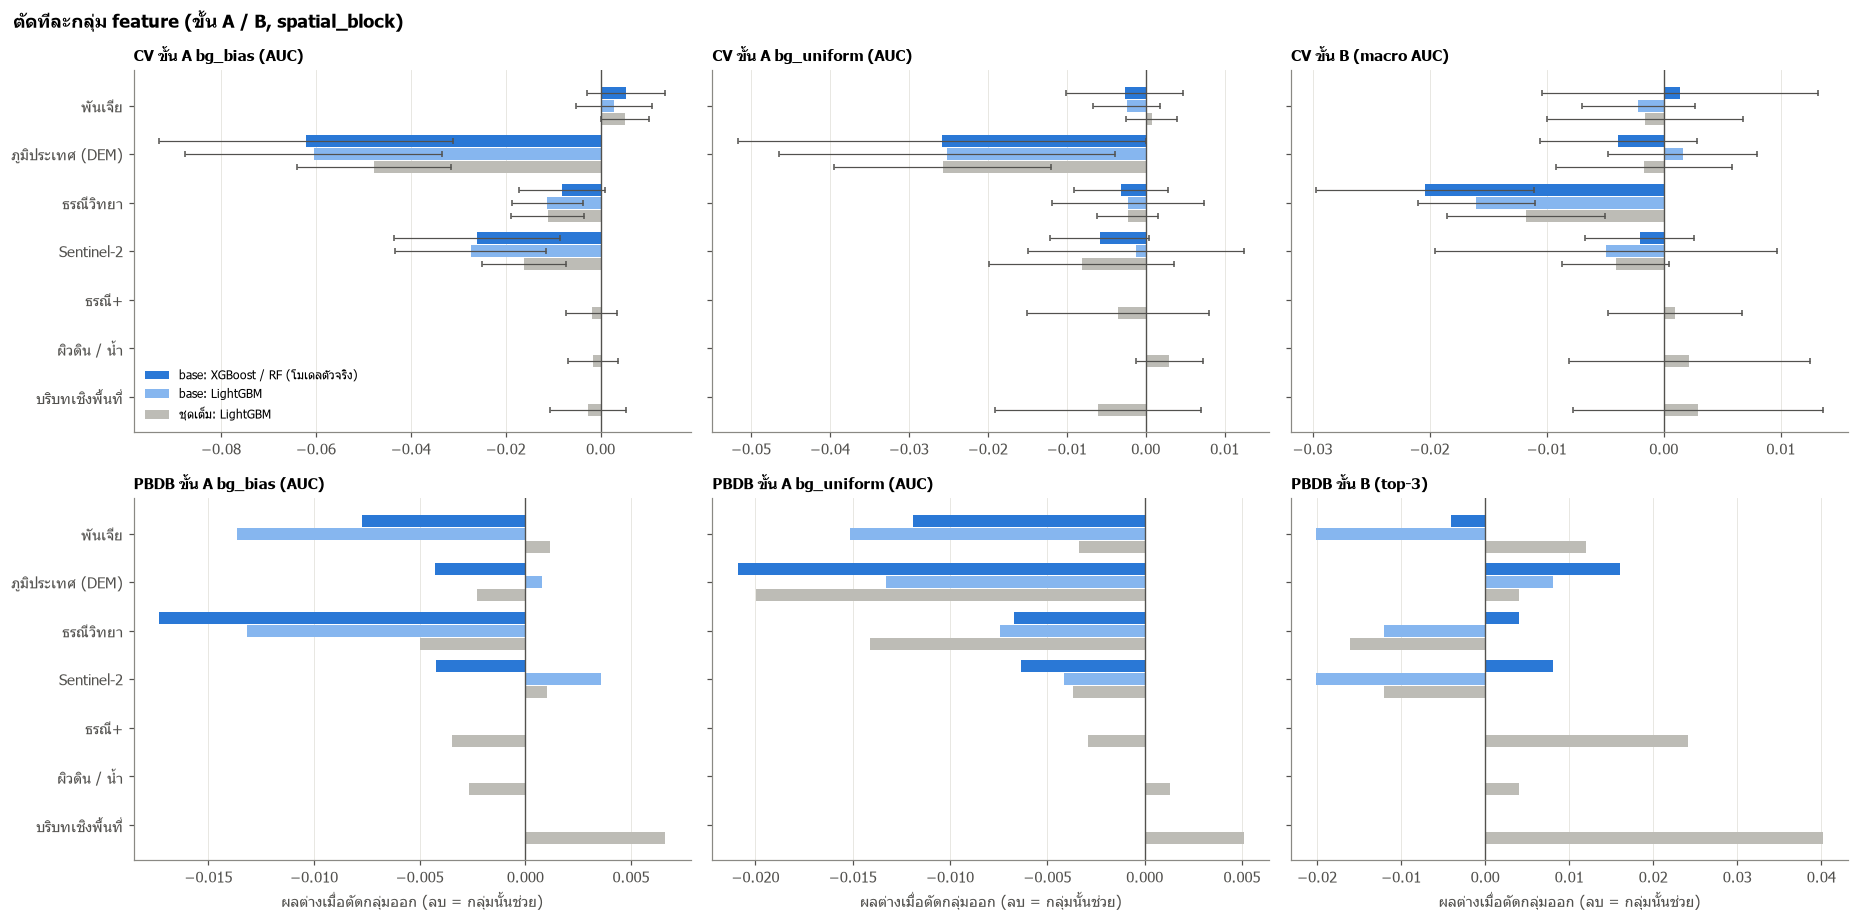

In [10]:
# กราฟ: ผลต่างเมื่อตัดแต่ละกลุ่ม (ค่าลบ = ตัดแล้วแย่ลง = กลุ่มนั้นช่วย) — แถวบน CV spatial_block (± SD ของ 5 fold), แถวล่าง PBDB
VARIANTS = [("base: XGBoost / RF (โมเดลตัวจริง)", "xgb", "rf", "base", "#2a78d6"), ("base: LightGBM", "lgbm", "lgbm", "base", "#86b6ef"),
            ("ชุดเต็ม: LightGBM", "lgbm", "lgbm", "+geo+surface+spatial", "#bdbcb6")]
GNAME = {"pangea": "พันเจีย", "dem": "ภูมิประเทศ (DEM)", "geology": "ธรณีวิทยา", "s2": "Sentinel-2", "geo_plus": "ธรณี+", "surface": "ผิวดิน / น้ำ",
         "spatial": "บริบทเชิงพื้นที่"}
ALLG = list(GNAME)


def dropped_set(ref, g):
    if ref == "+geo+surface+spatial":
        return "+geo+surface" if g == "spatial" else f"full-{g}"
    return f"base-{g}" if g in BASE_GROUPS else None


fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), sharey=True)
panels = [("CV ขั้น A bg_bias (AUC)", "A bg_bias", None), ("CV ขั้น A bg_uniform (AUC)", "A bg_uniform", None), ("CV ขั้น B (macro AUC)", "B", None),
          ("PBDB ขั้น A bg_bias (AUC)", None, "AUC bg_bias"), ("PBDB ขั้น A bg_uniform (AUC)", None, "AUC bg_uniform"), ("PBDB ขั้น B (top-3)", None, "B top3")]
y = np.arange(len(ALLG))
for ax, (title, key, col) in zip(axes.ravel(), panels):
    for j, (lab, ma, mb, ref, color) in enumerate(VARIANTS):
        m = mb if (key == "B" or col == "B top3") else ma
        vals, errs = [], []
        for g in ALLG:
            fs = dropped_set(ref, g)
            if fs is None:
                vals.append(np.nan); errs.append(0)
            elif key:
                reg, metric = RES[key]
                _, dm, ds, _, _ = fold_delta(reg, metric, f"{m}@{ref}", f"{m}@{fs}")
                vals.append(dm); errs.append(ds)
            else:
                vals.append(tPB.loc[f"{m}@{fs}", col] - tPB.loc[f"{m}@{ref}", col]); errs.append(0)
        ax.barh(y + (j - 1) * 0.27, vals, height=0.25, xerr=errs if key else None, color=color, label=lab,
                error_kw={"elinewidth": 0.8, "capsize": 2, "ecolor": INK})
    ax.axvline(0, color=INK, lw=0.9)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0, 0].set_yticks(y, [GNAME[g] for g in ALLG])
axes[0, 0].invert_yaxis()
for ax in axes[1]:
    ax.set_xlabel("ผลต่างเมื่อตัดกลุ่มออก (ลบ = กลุ่มนั้นช่วย)")
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("ตัดทีละกลุ่ม feature (ขั้น A / B, spatial_block)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

**โมเดลตัวจริง: base เทียบ base ที่ตัดพันเจีย** — ช่วงความเชื่อมั่น 95% ของผลต่างบน PBDB แบบ bootstrap จับคู่
(สุ่ม collection PBDB และจุดสุ่มชุดเดียวกันให้ทั้งสองโมเดล 1,000 รอบสำหรับขั้น A, 300 รอบสำหรับขั้น B)

In [11]:
rng = np.random.default_rng(0)
aucf = lambda p, g: ml.roc_auc_score(np.r_[np.ones(len(p)), np.zeros(len(g))], np.r_[p, g])
rows = []
for bg in regA:
    o = {e: regA["bg_uniform"].oof(f"spatial_block__xgb@{e}") for e in ["base", "base-pangea"]}
    s = {e: (pbdb_oof(regA[bg], f"xgb@{e}", "A"), o[e][o[e].y.eq(0)].sort_values("point_id").p.values) for e in o}
    d = []
    for _ in range(1000):
        ip, ir = rng.integers(0, len(pb), len(pb)), rng.integers(0, len(s["base"][1]), len(s["base"][1]))
        d.append(aucf(s["base-pangea"][0][ip], s["base-pangea"][1][ir]) - aucf(s["base"][0][ip], s["base"][1][ir]))
    rows.append({"เทียบ": f"ขั้น A {bg}: PBDB AUC (XGBoost)", "base": aucf(*s["base"]), "base-pangea": aucf(*s["base-pangea"]),
                 "Δ": np.mean(d), "95% CI ล่าง": np.percentile(d, 2.5), "95% CI บน": np.percentile(d, 97.5)})
has = YPB.sum(1) > 0
PBr = {e: pbdb_oof(regB, f"rf@{e}", "B")[has] for e in ["base", "base-pangea"]}
for k in ["macro_auc", "top3"]:
    full = {e: ml.multilabel_metrics(YPB[has], PBr[e], min_pos=5)[k] for e in PBr}
    d = []
    for _ in range(300):
        i = rng.integers(0, has.sum(), has.sum())
        d.append(ml.multilabel_metrics(YPB[has][i], PBr["base-pangea"][i], min_pos=5)[k] - ml.multilabel_metrics(YPB[has][i], PBr["base"][i], min_pos=5)[k])
    rows.append({"เทียบ": f"ขั้น B: PBDB {k} (Random Forest)", "base": full["base"], "base-pangea": full["base-pangea"],
                 "Δ": np.nanmean(d), "95% CI ล่าง": np.nanpercentile(d, 2.5), "95% CI บน": np.nanpercentile(d, 97.5)})
tPG = pd.DataFrame(rows).set_index("เทียบ")
tPG.style.format("{:.3f}")

,base,base-pangea,Δ,95% CI ล่าง,95% CI บน
เทียบ,,,,,
ขั้น A bg_bias: PBDB AUC (XGBoost),0.813,0.805,-0.008,-0.016,-0.000
ขั้น A bg_uniform: PBDB AUC (XGBoost),0.792,0.780,-0.012,-0.023,-0.002
ขั้น B: PBDB macro_auc (Random Forest),0.716,0.721,0.006,-0.012,0.025
ขั้น B: PBDB top3 (Random Forest),0.546,0.542,-0.004,-0.042,0.044


### feature ใหม่ที่โมเดลใช้มากสุด (LightGBM `+geo+surface+spatial`, `spatial_block`, เฉลี่ย 5 fold)

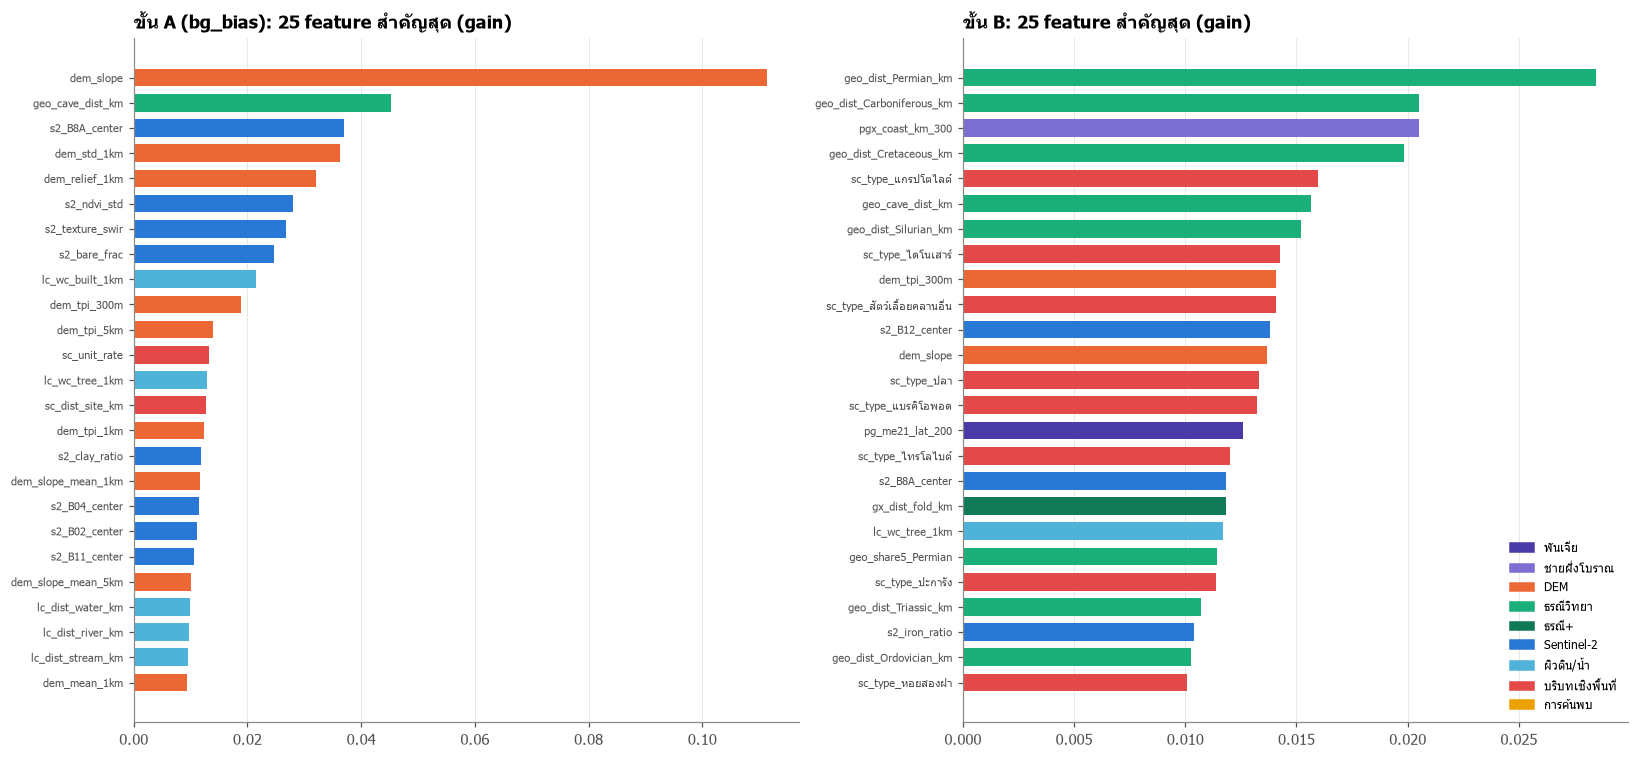

In [12]:
def fold_importance(reg, exp):
    imps = []
    for k in range(ml.N_FOLDS):
        b = ml.joblib.load(reg.model_path(exp, k))
        ms = b["model"] if isinstance(b["model"], list) else [b["model"]]
        imp = np.mean([m.booster_.feature_importance("gain") for m in ms if m is not None], axis=0)
        imps.append(pd.Series(imp / imp.sum(), index=b["pre"].num_cols + b["pre"].cat_cols))
    return pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)


grp_color = {"pg_": "#4a3aa7", "pgx": "#7d6fd1", "dem": "#eb6834", "geo": "#1baf7a", "gx_": "#0f7a55", "s2_": "#2a78d6",
             "lc_": "#4fb3d9", "sc_": "#e34948", "dc_": "#eda100"}
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, (reg, exp, title) in zip(axes, [(regA["bg_bias"], "spatial_block__lgbm@+geo+surface+spatial", "ขั้น A (bg_bias)"),
                                        (regB, "spatial_block__lgbm@+geo+surface+spatial", "ขั้น B")]):
    imp = fold_importance(reg, exp).head(25)[::-1]
    ax.barh(imp.index, imp.values, color=[grp_color.get(c[:3], MUTED) for c in imp.index], height=0.7)
    ax.set_title(f"{title}: 25 feature สำคัญสุด (gain)")
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(axis="y", visible=False)
names = {"pg_": "พันเจีย", "pgx": "ชายฝั่งโบราณ", "dem": "DEM", "geo": "ธรณีวิทยา", "gx_": "ธรณี+", "s2_": "Sentinel-2",
         "lc_": "ผิวดิน/น้ำ", "sc_": "บริบทเชิงพื้นที่", "dc_": "การค้นพบ"}
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in grp_color.values()], list(names.values()), frameon=False, loc="lower right", fontsize=8)
plt.tight_layout()

## 5. โมเดลตัวจริง (ตามที่ตกลงหลังดูผล)

- **ขั้น A**: XGBoost + `+geo+surface+spatial` ทั้ง `bg_bias` และ `bg_uniform`; **ขั้น B**: คง RF ชุดเดิม (notebook 10) เพราะกลุ่มใหม่ไม่ช่วย
- บริบทเชิงพื้นที่ของแถว train และของทุกจุดที่จะทำนาย (กริด, พิกัดใหม่) คำนวณจากแหล่ง ทธ. **ทั้งหมด ยกเว้นแหล่งในบล็อก 50 กม. เดียวกับจุดนั้น**
  — แบบเดียวกับ `spatial_block` ที่ใช้วัดผล และกันแหล่งเห็นตัวเอง (ระยะ 0 กม.)
- AOA คำนวณใหม่ด้วยชุด feature นี้; บันทึก `models/task2/final/A_<bg>_fe_xgb.joblib`, `aoa_A_<bg>_fe.joblib`, `final_meta_fe.json`
  (notebook 10b / 12 ใช้เมื่อ `deploy.stage_A_variant = "fe"` ใน `final_meta.json`)

In [13]:
FINAL = ml.MODELS / "task2" / "final"
NUM_FE, CAT_FE = cols_for("+geo+surface+spatial", "A")
sc_all = fl.spatial_context(allf, sites, allf.group_spatial_block.values, sites.group_spatial_block.values)
allf_fe = pd.concat([allf.drop(columns=[c for c in SC_A if c in allf]), sc_all], axis=1)
meta_fe = {"variant": "+geo+surface+spatial", "model": "xgb", "features": {"num": NUM_FE, "cat": CAT_FE},
           "spatial_context": {"cols": SC_A, "exclude": "same 50 km spatial block", "reference": "all DMR sites"},
           "extra_groups": ["geo_plus", "surface"], "stage_A": {}}
for bg in ml.tqdm_auto()(["bg_bias", "bg_uniform"], desc="โมเดลตัวจริง"):
    d = allf_fe[allf_fe.source.isin(["dmr_site", bg])].reset_index(drop=True)
    y = d.source.eq("dmr_site").astype(int).values
    path = FINAL / f"A_{bg}_fe_xgb.joblib"
    ml.fit_final_tabular("xgb", d, y, NUM_FE, CAT_FE, path)          # ใช้ไฟล์เดิมถ้า fingerprint ตรง
    aoa = ml.AOA().fit(d, NUM_FE, ml.tree_importance(path).reindex(NUM_FE).fillna(0).values, d.fold_spatial_block.values)
    ml.joblib.dump(aoa, FINAL / f"aoa_A_{bg}_fe.joblib", compress=3)
    t = table(regA[bg], "auc")["spatial_block"]
    meta_fe["stage_A"][bg] = {"tabular": path.name, "aoa": f"aoa_A_{bg}_fe.joblib",
                              "cv_auc_spatial_block": {"xgb@base": round(float(t["xgb@base"]), 4), "xgb@fe": round(float(t["xgb@+geo+surface+spatial"]), 4)},
                              "aoa_threshold": round(aoa.threshold_, 4), "aoa_pbdb_inside": round(float(aoa.inside(pb.merge(sc_all.assign(point_id=allf.point_id.values), on="point_id", suffixes=("_x", ""))).mean()), 4)}
(FINAL / "final_meta_fe.json").write_text(json.dumps(meta_fe, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(meta_fe["stage_A"], ensure_ascii=False, indent=1))

โมเดลตัวจริง: 100%|██████████| 2/2 [00:00<00:00,  2.29it/s]


{
 "bg_bias": {
  "tabular": "A_bg_bias_fe_xgb.joblib",
  "aoa": "aoa_A_bg_bias_fe.joblib",
  "cv_auc_spatial_block": {
   "xgb@base": 0.8867,
   "xgb@fe": 0.8934
  },
  "aoa_threshold": 0.5472,
  "aoa_pbdb_inside": 0.8621
 },
 "bg_uniform": {
  "tabular": "A_bg_uniform_fe_xgb.joblib",
  "aoa": "aoa_A_bg_uniform_fe.joblib",
  "cv_auc_spatial_block": {
   "xgb@base": 0.9301,
   "xgb@fe": 0.93
  },
  "aoa_threshold": 0.4636,
  "aoa_pbdb_inside": 0.8759
 }
}


## 6. ตรวจกับทั้งประเทศ: PBDB เทียบกริด 5 กม. (base vs fe)

โมเดลตัวจริงทั้งสองแบบ (train ด้วยข้อมูลทั้งหมด) ทำนาย PBDB 290 collection และกริด 20,706 จุดบนแผ่นดิน — แบบเดียวกับ notebook 10b
ช่วงความเชื่อมั่นจาก bootstrap แบบจับคู่ (สุ่ม PBDB และกริดชุดเดียวกันให้ทั้งสองโมเดล 300 รอบ)

In [14]:
grid = pd.read_parquet(ml.FEAT / "grid_5km.parquet")
G = (grid.merge(fl.batch_pangea(grid, tag="grid_"), on="point_id").merge(fl.batch_dem(grid, tag="grid_"), on="point_id")
     .merge(fl.batch_geology(grid, tag="grid_"), on="point_id").merge(fl.batch_s2_indices(grid, ml.FEAT / "s2" / "grid_patches", tag="grid_"), on="point_id", how="left")
     .merge(pd.read_parquet(ml.FEAT / "extra_grid.parquet"), on="point_id", how="left"))
for c in CAT:
    G[c] = G[c].astype(str)
G = pd.concat([G, fl.spatial_context(G, sites, fl.block_group(G.lon, G.lat), sites.group_spatial_block.values)], axis=1)
pbx = pd.concat([pb.reset_index(drop=True), fl.spatial_context(pb.reset_index(drop=True), sites, pb.group_spatial_block.values, sites.group_spatial_block.values)], axis=1)
rng = np.random.default_rng(0)
auc = lambda p, g: ml.roc_auc_score(np.r_[np.ones(len(p)), np.zeros(len(g))], np.r_[p, g])
rows = []
for bg in ["bg_bias", "bg_uniform"]:
    sb = (ml.predict_bundle(FINAL / META["stage_A"][bg]["tabular"], pbx), ml.predict_bundle(FINAL / META["stage_A"][bg]["tabular"], G))
    sf = (ml.predict_bundle(FINAL / meta_fe["stage_A"][bg]["tabular"], pbx), ml.predict_bundle(FINAL / meta_fe["stage_A"][bg]["tabular"], G))
    d = []
    for _ in range(300):
        ip, ig = rng.integers(0, len(pbx), len(pbx)), rng.integers(0, len(G), 5000)
        d.append(auc(sf[0][ip], sf[1][ig]) - auc(sb[0][ip], sb[1][ig]))
    gr = G.geo_rock_sym.str.endswith("gr").values
    if bg == "bg_bias":                    # ตัวอย่างพื้นที่ป่าบนภูเขา: ดอยอินทนนท์ (98.487°E, 18.589°N) — อันดับของกริดใกล้สุดในทั้งประเทศ
        iD = int(np.argmin((G.lon.values - 98.487) ** 2 + (G.lat.values - 18.589) ** 2))
        print(f"ดอยอินทนนท์ (กริด {G.lon.iat[iD]:.3f}, {G.lat.iat[iD]:.3f}; หิน {G.geo_rock_sym.iat[iD]}) อันดับใน {bg}: "
              f"base {pd.Series(sb[1]).rank(pct=True).iat[iD]:.0%} → fe {pd.Series(sf[1]).rank(pct=True).iat[iD]:.0%}")
    rows.append({"background": bg, "AUC base": auc(*sb), "AUC fe": auc(*sf), "Δ": np.mean(d), "95% CI ล่าง": np.percentile(d, 2.5),
                 "95% CI บน": np.percentile(d, 97.5), "KS base": ml.ks_vs_random(*sb), "KS fe": ml.ks_vs_random(*sf),
                 "อันดับเฉลี่ยหินแกรนิต base": pd.Series(sb[1]).rank(pct=True)[gr].mean(), "อันดับเฉลี่ยหินแกรนิต fe": pd.Series(sf[1]).rank(pct=True)[gr].mean()})
pd.DataFrame(rows).set_index("background").style.format("{:.3f}")

ธรณีวิทยา (chunk): 100%|██████████| 11/11 [00:00<00:00, 180.74it/s]
ดัชนี Sentinel-2: 0it [00:00, ?it/s]


ดอยอินทนนท์ (กริด 98.479, 18.585; หิน PE) อันดับใน bg_bias: base 48% → fe 74%


,AUC base,AUC fe,Δ,95% CI ล่าง,95% CI บน,KS base,KS fe,อันดับเฉลี่ยหินแกรนิต base,อันดับเฉลี่ยหินแกรนิต fe
background,,,,,,,,,
bg_bias,0.796,0.784,-0.012,-0.024,-0.002,0.474,0.438,0.286,0.330
bg_uniform,0.814,0.809,-0.004,-0.012,0.004,0.506,0.503,0.284,0.298


## 7. ตรวจกับทั้งประเทศ: ตัดพันเจียจากโมเดลตัวจริง

train XGBoost ขั้น A ด้วย base ที่ตัด `pg_` ทั้งหมด ด้วยข้อมูลทั้งหมด (เก็บใน `models/task2/FE/final_nopangea/` ไม่แตะโมเดลที่ใช้จริง)
แล้วเทียบกับโมเดลตัวจริงบน PBDB เทียบกริด 5 กม. ทั้งประเทศ แบบเดียวกับหัวข้อ 6 และดูว่าแผนที่เปลี่ยนไปแค่ไหน

In [15]:
from scipy.stats import spearmanr

NOPG = ml.MODELS / "task2" / "FE" / "final_nopangea"
NOPG.mkdir(parents=True, exist_ok=True)
NUM_NP, CAT_NP = FS["base-pangea"]
rows = []
for bg in ["bg_bias", "bg_uniform"]:
    d = allf[allf.source.isin(["dmr_site", bg])].reset_index(drop=True)
    y = d.source.eq("dmr_site").astype(int).values
    path = NOPG / f"A_{bg}_nopangea_xgb.joblib"
    ml.fit_final_tabular("xgb", d, y, NUM_NP, CAT_NP, path)
    sb = (ml.predict_bundle(FINAL / META["stage_A"][bg]["tabular"], pbx), ml.predict_bundle(FINAL / META["stage_A"][bg]["tabular"], G))
    sn = (ml.predict_bundle(path, pbx), ml.predict_bundle(path, G))
    dd = []
    for _ in range(300):
        ip, ig = rng.integers(0, len(pbx), len(pbx)), rng.integers(0, len(G), 5000)
        dd.append(auc(sn[0][ip], sn[1][ig]) - auc(sb[0][ip], sb[1][ig]))
    rb, rn = pd.Series(sb[1]).rank(pct=True), pd.Series(sn[1]).rank(pct=True)
    top_b, top_n = rb >= 0.9, rn >= 0.9
    rows.append({"background": bg, "AUC base": auc(*sb), "AUC ตัดพันเจีย": auc(*sn), "Δ": np.mean(dd), "95% CI ล่าง": np.percentile(dd, 2.5),
                 "95% CI บน": np.percentile(dd, 97.5), "KS base": ml.ks_vs_random(*sb), "KS ตัดพันเจีย": ml.ks_vs_random(*sn),
                 "Spearman อันดับกริด": spearmanr(sb[1], sn[1]).statistic, "10% บนสุดซ้อนกัน": (top_b & top_n).sum() / top_b.sum()})
tNP = pd.DataFrame(rows).set_index("background")
tNP.style.format("{:.3f}")

,AUC base,AUC ตัดพันเจีย,Δ,95% CI ล่าง,95% CI บน,KS base,KS ตัดพันเจีย,Spearman อันดับกริด,10% บนสุดซ้อนกัน
background,,,,,,,,,
bg_bias,0.796,0.783,-0.013,-0.022,-0.006,0.474,0.423,0.948,0.823
bg_uniform,0.814,0.795,-0.018,-0.028,-0.009,0.506,0.459,0.930,0.821


## สรุป

**ขั้น A — โอกาสพบซาก** (AUC `spatial_block`; Δ = ค่าเฉลี่ยผลต่างต่อ fold เทียบ base ± SD ของ 5 fold)

| ชุด feature | `bg_bias` | Δ (`bg_bias`) | `bg_uniform` | PBDB AUC (`bg_bias`) |
|---|---|---|---|---|
| LightGBM base | 0.884 | — | 0.928 | 0.806 |
| + geo | 0.882 | −0.002 ± 0.006 | 0.934 | 0.817 |
| + surface | 0.888 | +0.004 ± 0.005 | 0.925 | 0.805 |
| + spatial | 0.885 | +0.001 ± 0.007 | 0.931 | 0.797 |
| + geo + surface + spatial | 0.890 | +0.006 ± 0.010 | 0.932 | 0.807 |
| XGBoost base → **+ geo + surface + spatial (ใช้จริง)** | 0.887 → **0.893** | +0.007 ± 0.008 (ดีขึ้น 4/5 fold) | 0.930 → 0.930 | 0.813 → 0.811 |
| + discovery *(ทดลองแยก)* | 0.898 | **+0.014 ± 0.008 (5/5 fold)** | 0.930 | 0.811 |
| discovery อย่างเดียว | 0.775 | | 0.797 | 0.659 |

- **กลุ่มธรรมชาติใหม่ช่วยน้อยมาก** — ทุกค่าอยู่ในช่วงความแปรปรวนระหว่าง fold; โมเดลใช้ feature ใหม่จริง (สิ่งปลูกสร้าง/ป่าใน 1 กม., อัตราพบซากต่อหน่วยหิน,
  ระยะถึงแหล่งอ้างอิง; ขั้น B: ชายฝั่งโบราณ 300 ล้านปี และประเภทซากของแหล่งใกล้เคียง) แต่ส่วนใหญ่*แทน*ข้อมูลที่ feature เดิม (DEM, ธรณีวิทยา, Sentinel-2,
  พันเจีย) มีอยู่แล้ว — สอดคล้องกับงานที่ว่าหน่วยหิน + การเปิดเผยของหินเป็นตัวกำหนดหลัก
- **การค้นพบเป็นกลุ่มเดียวที่ช่วยสม่ำเสมอ** และอย่างเดียวได้ AUC 0.775 → แหล่งที่รู้จักสะท้อน "ที่ที่คนไปถึง/ขุด" (ถนน, พื้นที่แร่, แอ่งเกลือ) ตาม Block et al. 2016
  — **ไม่ใช้ในโมเดลตัวจริง** ตามที่ตกลง เพื่อไม่ให้แผนที่เอนเอียงตามถนน
- **ขั้น B — ประเภทซาก** (label หลังตรวจทาน): ไม่มีกลุ่มใดช่วย (LightGBM 0.735–0.745 vs base 0.742; RF 0.756–0.757 vs 0.758);
  บริบทเชิงพื้นที่ทำให้ PBDB แย่ลง (top-3 0.526 → 0.474)
  → **คง RF ชุดเดิม**
- **ตัดสินใจ 2 รอบ**: รอบแรกเลือก XGBoost + `geo + surface + spatial` (CV ดีขึ้น +0.007) แล้ว train ตัวจริง (`A_<bg>_fe_xgb.joblib`, `final_meta_fe.json`)
  แต่**ทดสอบ PBDB กับกริดทั้งประเทศแย่ลง**สำหรับ `bg_bias`: AUC 0.796 → 0.784 (Δ −0.012, 95% CI −0.024…−0.002), KS 0.474 → 0.438
  และพื้นที่ป่าบนหินที่ไม่ค่อยมีซากถูกดันอันดับขึ้น (หินแกรนิต: อันดับเฉลี่ยในกริด 0.286 → 0.330; กริดที่ดอยอินทนนท์ 48% → 74%)
  — แหล่งที่รู้จักมีป่ามากกว่า (ถ้ำหินปูนในป่า) จึงจับคู่ป่ากับซากแบบไม่ทั่วไป
  → **ตกลงกลับมาใช้ base** (`deploy.stage_A_variant = "base"`); โมเดล fe และผลเทียบเก็บไว้ในโฟลเดอร์ final และหัวข้อ 6
- บทเรียน: `spatial_block` CV ยังดูเฉพาะพื้นที่ใกล้แหล่งที่รู้จัก ควรตรวจกับทั้งประเทศ (PBDB vs กริด) ก่อนเปลี่ยนโมเดลตัวจริงเสมอ

**ตัดทีละกลุ่ม — พันเจียช่วยจริงไหม** (โมเดลตัวจริง XGBoost ขั้น A / RF ขั้น B, ชุด base)

| ตรวจด้วย | base | ตัดพันเจีย | Δ (95% CI) |
|---|---|---|---|
| CV `spatial_block` ขั้น A `bg_bias` / `bg_uniform` | 0.887 / 0.930 | 0.892 / 0.927 | +0.005 ± 0.008 (3/5 fold) / −0.003 ± 0.007 |
| CV ขั้น B (macro AUC) | 0.758 | 0.759 | +0.001 ± 0.012 |
| PBDB out-of-fold ขั้น A `bg_bias` / `bg_uniform` | 0.813 / 0.792 | 0.805 / 0.780 | −0.008 (−0.016…−0.000) / −0.012 (−0.023…−0.002) |
| PBDB ขั้น B top-3 | 0.546 | 0.542 | −0.004 (−0.042…+0.044) |
| **PBDB เทียบกริดทั้งประเทศ** (โมเดล train ทั้งหมด) `bg_bias` / `bg_uniform` | 0.796 / 0.814 | 0.783 / 0.795 | **−0.013 (−0.022…−0.006) / −0.018 (−0.028…−0.009)** |

- **CV มองไม่เห็นประโยชน์ของพันเจีย** (ตัดแล้วเท่าเดิมหรือดีขึ้นเล็กน้อย ในระดับ noise) แต่**ข้อมูลอิสระเห็น**: ตัดแล้ว PBDB เทียบกริดทั้งประเทศแย่ลงทั้งสอง background
  (CI ไม่คร่อม 0) และ KS ลดลง (0.474 → 0.423, 0.506 → 0.459) — กลับด้านกับกรณีเพิ่ม feature ที่ CV ดีขึ้นแต่ทั้งประเทศแย่ลง
  แผนที่สองแบบคล้ายกันมาก (Spearman ของอันดับกริด 0.948 / 0.930, พื้นที่ 10% บนสุดซ้อนกัน 82%) → **คงพันเจียในโมเดลตัวจริง**; ขั้น B ไม่ต่างกัน
- **กลุ่มอื่น** (CV `spatial_block`, โมเดลตัวจริง): ภูมิประเทศสำคัญที่สุดสำหรับขั้น A (ตัดแล้ว `bg_bias` 0.887 → 0.825, แย่ลงทุก fold),
  Sentinel-2 รองลงมา (0.861), ธรณีวิทยาสำคัญที่สุดสำหรับขั้น B (0.758 → 0.737, แย่ลงทุก fold);
  กลุ่มใหม่ (ธรณี+, ผิวดิน, บริบทเชิงพื้นที่) ตัดออกจากชุดเต็มแล้วเปลี่ยนไม่เกิน ±0.006 — สอดคล้องกับผลเพิ่มกลุ่มด้านบน